<a href="https://colab.research.google.com/github/Junaeid-Shoaib/fashion-mnist-pytorch/blob/main/Gpu_ann_fashion_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
#important libraries
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

#set seed for reproducibilty
torch.manual_seed(42)

In [55]:
#Check gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [56]:
df = pd.read_csv('fashion-mnist_train.csv')

In [57]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


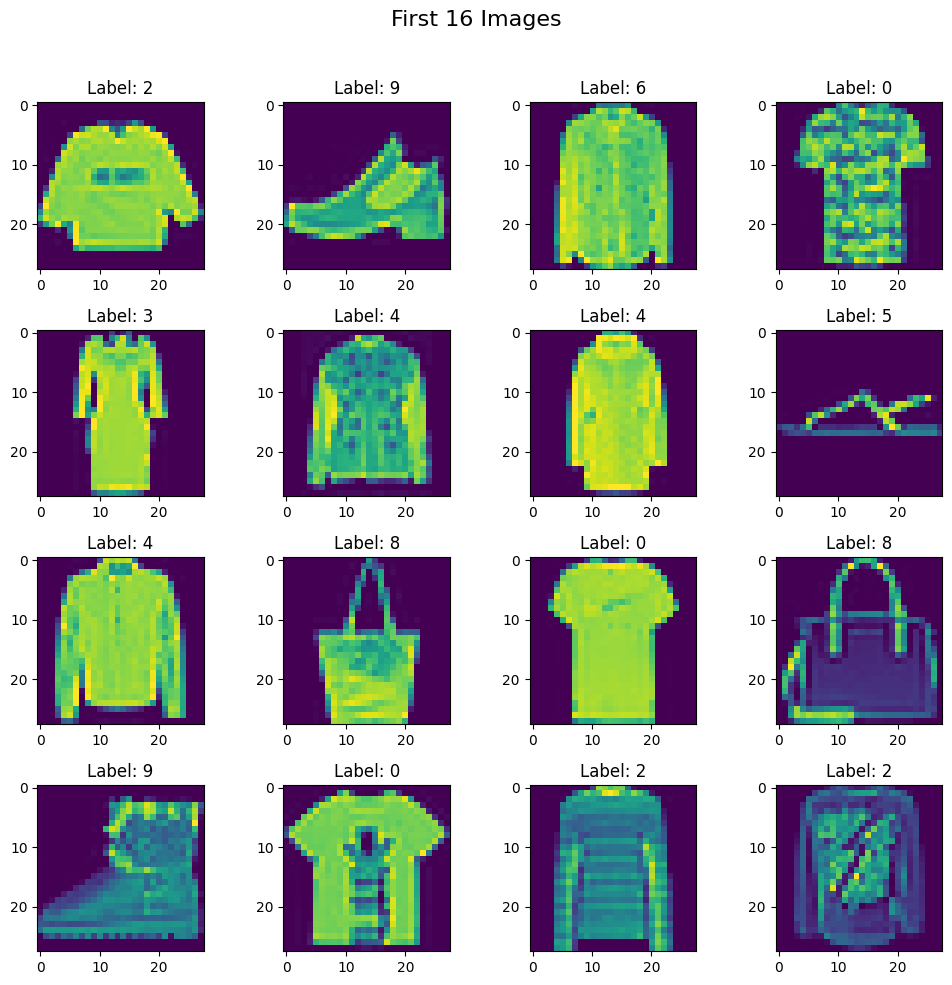

In [58]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    # ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()


In [59]:
df.shape

(60000, 785)

In [60]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [62]:
X_train.shape

(48000, 784)

In [63]:
y_train.shape

(48000,)

In [64]:
#scaling
X_train = X_train / 255.0
X_test = X_test / 255.0

In [65]:
X_train

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.00392157, 0.        ,
        0.        ]], shape=(48000, 784))

In [66]:
#create custom dataset
class CustomDataset(Dataset):
  def __init__(self, features, labels):
    self.features = torch.tensor(features, dtype=torch.float32)
    self.labels = torch.tensor(labels, dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, idx):
    return self.features[idx], self.labels[idx]


In [67]:
#create obj
train_dataset = CustomDataset(X_train, y_train)
test_dataset = CustomDataset(X_test, y_test)

In [68]:
len(train_dataset)

48000

In [69]:
train_dataset[0]

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2275,
         0.5333, 0.0000, 0.0

In [70]:
#data loader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)

In [71]:
#define nn class

class myANN(nn.Module):
  def __init__(self, num_features):
    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.BatchNorm1d(128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 64),
        nn.BatchNorm1d(64),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(64, 10)
    )

  def forward(self, x):
    return self.model(x)

In [75]:
#parameters
epochs = 100
learning_rate = 0.01

In [76]:
#instentiate the model
model = myANN(X_train.shape[1])

model.to(device)

#loss function
loss_fn = nn.CrossEntropyLoss()

#optimizer
optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay = 1e-4)

In [77]:
 #training loop

for epoch in range(epochs):

   total_loss = 0.0
   for batch_features, batch_labels in train_loader:

        #move to gpu
        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        #forward pass
        outputs = model(batch_features)
        loss = loss_fn(outputs, batch_labels)
        optimizer.zero_grad()
        #backward pass
        loss.backward()
        #update grads
        optimizer.step()
        total_loss += loss.item()
   print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader)}")


Epoch 1/100, Loss: 0.8149842947324117
Epoch 2/100, Loss: 0.569710615336895
Epoch 3/100, Loss: 0.5139312370816866
Epoch 4/100, Loss: 0.4831556446254253
Epoch 5/100, Loss: 0.46181674880782764
Epoch 6/100, Loss: 0.44680031898617745
Epoch 7/100, Loss: 0.4305735356857379
Epoch 8/100, Loss: 0.41982877965271476
Epoch 9/100, Loss: 0.4104748903661966
Epoch 10/100, Loss: 0.4023650167087714
Epoch 11/100, Loss: 0.3951078443725904
Epoch 12/100, Loss: 0.38756326559682686
Epoch 13/100, Loss: 0.38223748716215294
Epoch 14/100, Loss: 0.3749958253453175
Epoch 15/100, Loss: 0.36743758130570253
Epoch 16/100, Loss: 0.3634848563869794
Epoch 17/100, Loss: 0.3634407731940349
Epoch 18/100, Loss: 0.3545333245247603
Epoch 19/100, Loss: 0.34932031441728273
Epoch 20/100, Loss: 0.3469862958714366
Epoch 21/100, Loss: 0.343636608466506
Epoch 22/100, Loss: 0.34346289381881556
Epoch 23/100, Loss: 0.3363040594557921
Epoch 24/100, Loss: 0.33469884684185186
Epoch 25/100, Loss: 0.3254913649012645
Epoch 26/100, Loss: 0.32147

In [78]:
#evaluation

model.eval()

myANN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [79]:
#evaluation code on test data
total_correct = 0
total_samples = 0

with torch.no_grad():
  for batch_features, batch_labels in test_loader:
    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)
    outputs = model(batch_features)
    _, predicted = torch.max(outputs, 1)
    total_samples += batch_labels.size(0)
    total_correct += (predicted == batch_labels).sum().item()
accuracy = total_correct / total_samples
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 89.36%


In [81]:
#evaluation code on train data
total_correct = 0
total_samples = 0

with torch.no_grad():
  for batch_features, batch_labels in train_loader:
    batch_features = batch_features.to(device)
    batch_labels = batch_labels.to(device)
    outputs = model(batch_features)
    _, predicted = torch.max(outputs, 1)
    total_samples += batch_labels.size(0)
    total_correct += (predicted == batch_labels).sum().item()
accuracy = total_correct / total_samples
print(f"Train Accuracy: {accuracy * 100:.2f}%")

Train Accuracy: 95.90%
